# 03 - Rental Demand & Temporal Patterns

**Objective:** describe how demand varies by hour, weekday, day type, month, season and year.
**Grain:** daily metrics come from `day.csv` (rentals per day); intraday metrics come from `hour.csv` (rentals per observed hour). They are labelled separately and never compared directly.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore", message="findfont")
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.visualization.style import apply_matplotlib_style
apply_matplotlib_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 40)
from src.data.clean import load_processed
from src.analysis import kpis as K
from src.visualization import figures as F
day, hour = load_processed("day"), load_processed("hour")

## Headline KPIs (daily grain)

In [2]:
K.kpi_frame(K.headline_kpis(day))

,name,value,unit,grain,note
0,Total rentals,"3,292,679.00",rentals,period total,2011-01-01 to 2012-12-31
1,Registered rentals,"2,672,662.00",rentals,period total,
2,Casual rentals,"620,017.00",rentals,period total,
3,Registered share,0.81,share,ratio,
4,Casual share,0.19,share,ratio,
5,Casual-to-registered ratio,0.23,ratio,ratio,
6,Mean daily rentals,"4,504.35",rentals,per day,
7,Median daily rentals,"4,548.00",rentals,per day,
8,Max daily rentals,"8,714.00",rentals,per day,2012-09-15
9,Min daily rentals,22.00,rentals,per day,2012-10-29


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


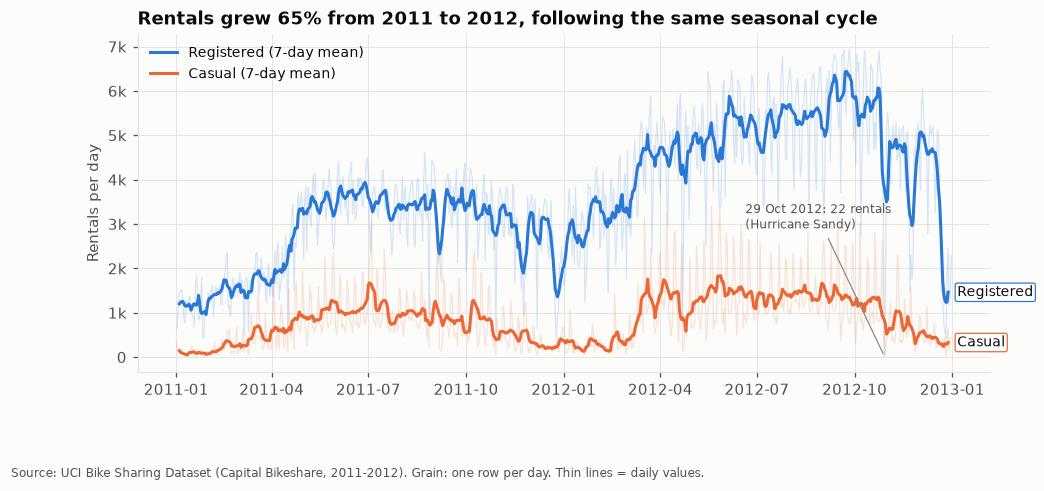

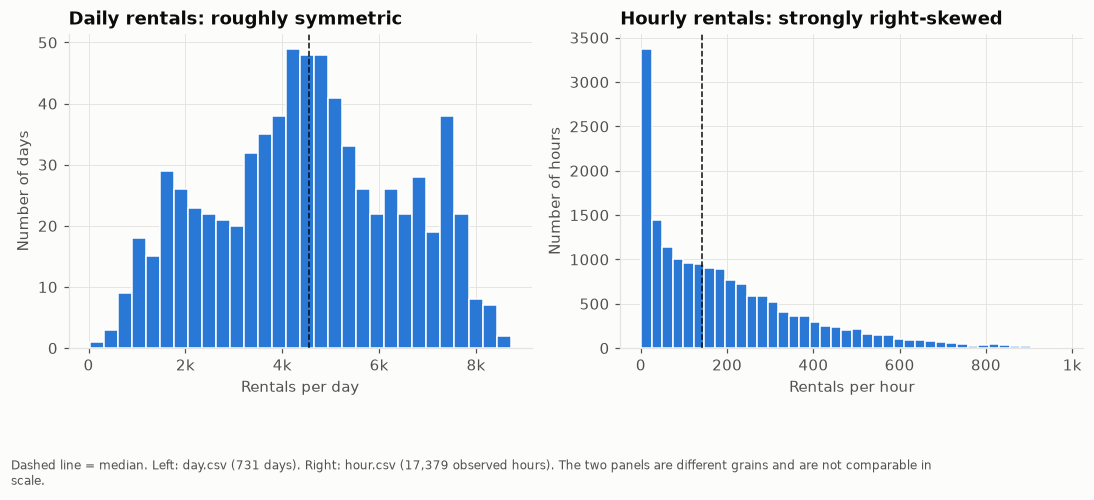

In [3]:
F.fig_daily_trend(day); plt.show()
F.fig_distributions(day, hour); plt.show()

- Daily rentals are roughly symmetric, so mean and median are close. Hourly rentals are strongly right-skewed (many quiet hours, few very busy ones). That is why medians and percentiles accompany the hourly means.
- The minimum day (22 rentals, 2012-10-29) is Hurricane Sandy. It is kept, as a genuine event rather than a data error.

## Year-over-year and monthly trend

,year_month,cnt,mean_daily_cnt,mom_change,yoy_change
12,2012-01-01,96744,"3,120.77",0.11,1.53
13,2012-02-01,103137,"3,556.45",0.07,1.14
14,2012-03-01,164875,"5,318.55",0.60,1.57
15,2012-04-01,174224,"5,807.47",0.06,0.84
16,2012-05-01,195865,"6,318.23",0.12,0.44
17,2012-06-01,202830,"6,761.00",0.04,0.41
18,2012-07-01,203607,"6,567.97",0.00,0.44
19,2012-08-01,214503,"6,919.45",0.05,0.57
20,2012-09-01,218573,"7,285.77",0.02,0.72
21,2012-10-01,198841,"6,414.23",-0.09,0.61


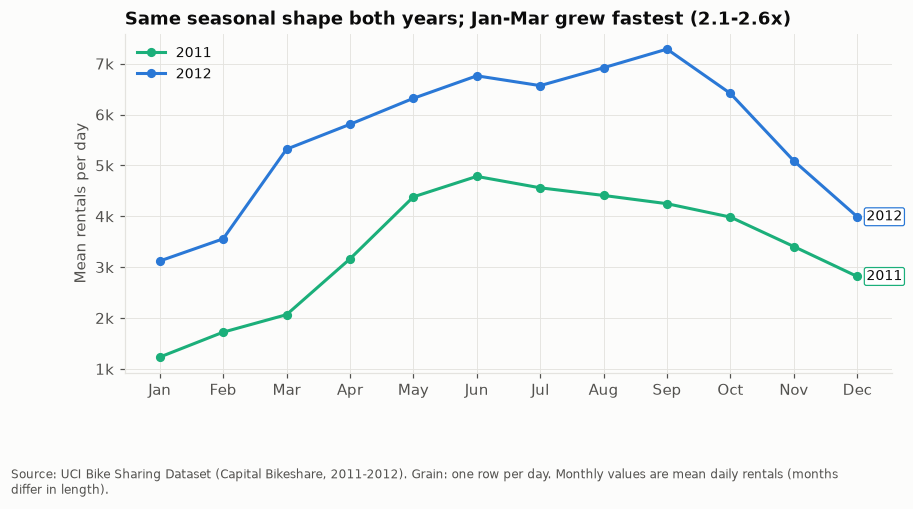

In [4]:
m = K.monthly_trend(day)
display(m[["year_month", "cnt", "mean_daily_cnt", "mom_change", "yoy_change"]].tail(12))
F.fig_monthly_by_year(day); plt.show()

## Intraday patterns (hourly grain)

,day_type,segment,peak_hour,peak_mean_per_hour,trough_hour,trough_mean_per_hour
0,Working day,cnt,17,525.29,3,4.94
1,Working day,casual,17,56.90,4,0.77
2,Working day,registered,17,468.39,3,4.03
3,Weekend,cnt,13,380.15,5,8.49
4,Weekend,casual,14,143.13,5,1.74
5,Weekend,registered,12,245.23,4,6.19
6,Holiday,cnt,13,298.52,4,5.85
7,Holiday,casual,13,105.05,5,1.57
8,Holiday,registered,17,217.86,4,4.05


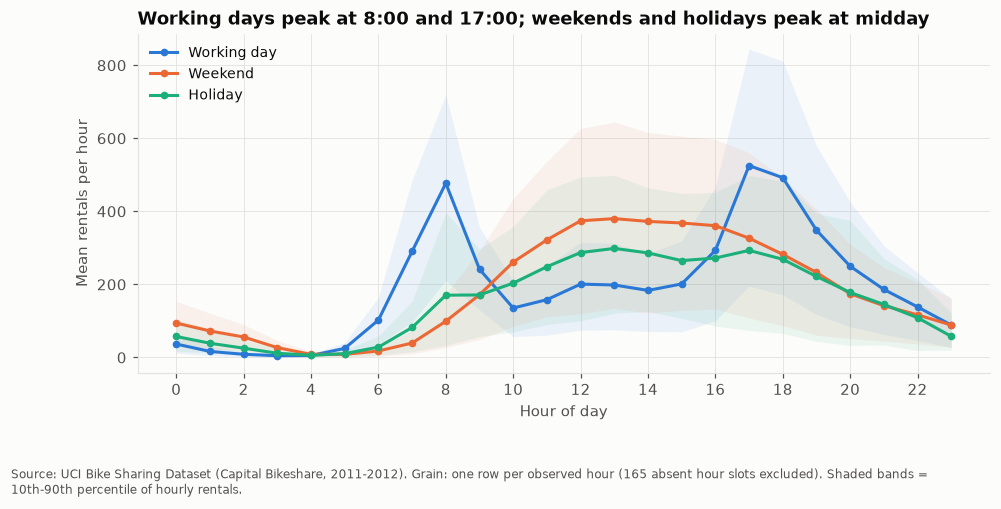

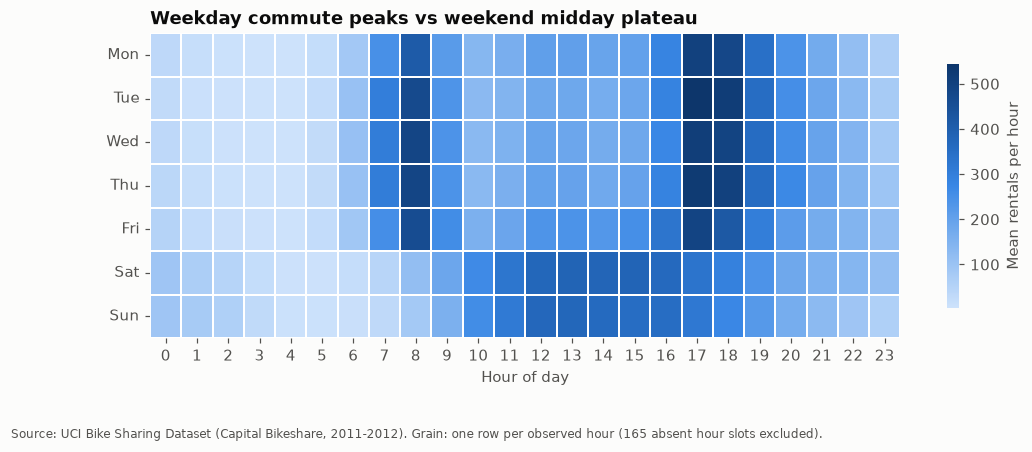

In [5]:
display(K.peak_hours(hour))
F.fig_hourly_by_daytype(hour); plt.show()
F.fig_hour_weekday_heatmap(hour); plt.show()

- **Working days** have two sharp peaks, at 08:00 and 17:00-18:00, a commuting signature.
- **Weekends and holidays** have a single broad plateau from about 11:00 to 17:00.
- The heatmap shows that the pattern is uniform Monday to Friday and switches abruptly on Saturday.

## Weekday and day type (daily grain)

,days,mean_cnt,median_cnt,mean_casual,mean_registered,total_cnt,casual_share
day_type,,,,,,,
Working day,500,"4,584.82","4,582.00",606.57,"3,978.25",2292410,0.13
Weekend,210,"4,389.69","4,467.50","1,401.78","2,987.91",921834,0.32
Holiday,21,"3,735.00","3,351.00","1,064.71","2,670.29",78435,0.29


,days,mean_cnt,median_cnt,mean_casual,mean_registered,total_cnt,casual_share
weekday_label,,,,,,,
Mon,105,"4,338.12","4,359.00",674.13,"3,663.99",455503,0.16
Tue,104,"4,510.66","4,576.50",556.18,"3,954.48",469109,0.12
Wed,104,"4,548.54","4,642.50",551.14,"3,997.39",473048,0.12
Thu,104,"4,667.26","4,721.00",590.96,"4,076.30",485395,0.13
Fri,104,"4,690.29","4,601.50",752.29,"3,938.00",487790,0.16
Sat,105,"4,550.54","4,521.00","1,465.26","3,085.29",477807,0.32
Sun,105,"4,228.83","4,334.00","1,338.30","2,890.53",444027,0.32


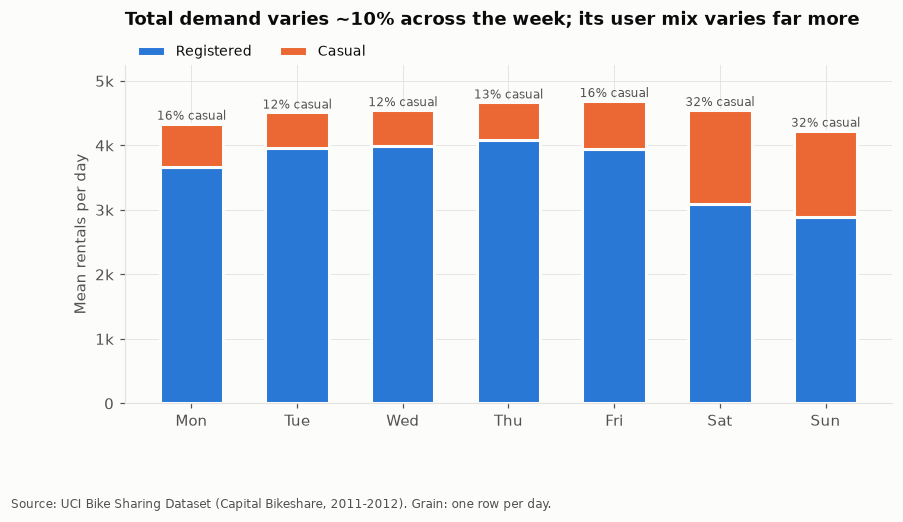

In [6]:
display(K.daily_summary_by(day, 'day_type'))
display(K.daily_summary_by(day, 'weekday_label'))
F.fig_weekday_segments(day); plt.show()

## Seasons (astronomical; see notebook 02)

,days,mean_cnt,median_cnt,mean_casual,mean_registered,total_cnt,casual_share
season_label,,,,,,,
Winter,181,"2,604.13","2,209.00",334.93,"2,269.20",471348,0.13
Spring,184,"4,992.33","4,941.50","1,106.10","3,886.23",918589,0.22
Summer,188,"5,644.30","5,353.50","1,202.61","4,441.69",1061129,0.21
Fall,178,"4,728.16","4,634.50",729.11,"3,999.05",841613,0.15


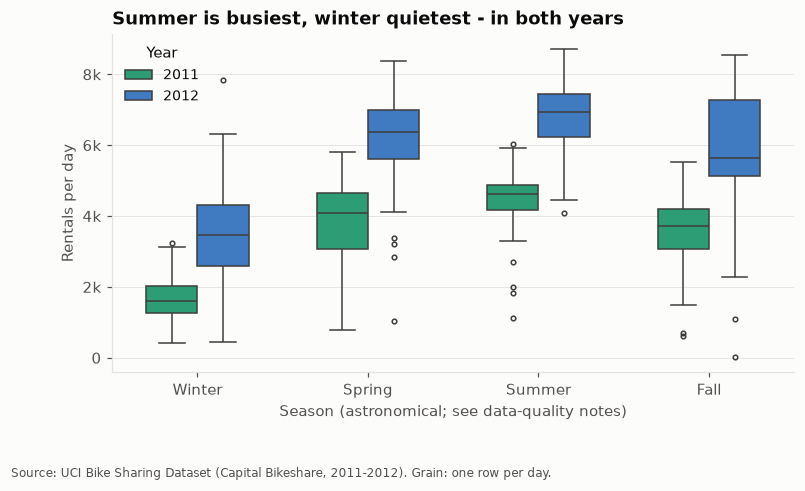

In [7]:
display(K.daily_summary_by(day, 'season_label'))
F.fig_season_box(day); plt.show()

## Conclusions
1. Rentals grew 65% from 2011 to 2012 on an unchanged seasonal cycle. January-March grew fastest.
2. The intraday shape depends on day type: two commute peaks on working days, a midday plateau on non-working days.
3. Total daily demand varies only about 10% across weekdays, but the user mix varies far more (studied in notebook 05).
4. Summer is the busiest season and winter the quietest, in both years.

**Limitations:** two years only, so the trend cannot be extrapolated; hourly means exclude 165 missing hour slots; holidays are few (21 days).